# 02 · ¿Qué hace que una víctima muera?

*Segundos contra vidas* · Hackathon de Datos 2026 · ITM

Regresión logística sobre el archivo de víctimas (D16): su conteo de muertos coincide con la cifra oficial.
Cada parte: código → conclusión → decisión.

## 0 · Configuración

In [1]:
import os, sys, unicodedata, re
from pathlib import Path

raiz = Path.cwd()
while not (raiz / "src" / "fuentes.py").exists():
    if raiz.parent == raiz:
        raise FileNotFoundError(f"No encontré el proyecto. El notebook está en: {Path.cwd()}")
    raiz = raiz.parent
os.chdir(raiz)
sys.path.insert(0, str(raiz))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.metrics import roc_auc_score, brier_score_loss
from src.descarga import leer

pd.set_option("display.max_columns", 40)
print("Proyecto:", raiz)

Proyecto: C:\Users\crist\Documents\segundos-contra-vidas


In [2]:
# Nombres de columnas uniformes: minúscula, sin tildes, con guion bajo
def _arreglar_texto(s):
    for codif in ("latin-1", "cp1252"):
        try:
            return s.encode(codif).decode("utf-8")
        except (UnicodeEncodeError, UnicodeDecodeError):
            pass
    return s

def normalizar_columnas(df):
    nuevas = []
    for c in df.columns:
        c = unicodedata.normalize("NFKD", _arreglar_texto(str(c))).encode("ascii", "ignore").decode()
        nuevas.append(re.sub(r"[^0-9a-z]+", "_", c.lower()).strip("_"))
    df.columns = nuevas
    return df

## 1 · Preparar los datos

#### 1.1 Carga y limpieza (D12)

In [3]:
vic = normalizar_columnas(leer("victimas_medata"))
vic = vic[vic["ano"].notna()].copy()                      # quita las filas vacías

vic["fecha"] = pd.to_datetime(vic["fecha_incidente"], dayfirst=True, errors="coerce")
vic["hora"] = pd.to_numeric(vic["hora"], errors="coerce")
vic["edad"] = pd.to_numeric(vic["edad"], errors="coerce")
vic["ano"] = vic["ano"].astype(int)
vic["muerto"] = (vic["gravedad_victima"] == "Muertos").astype(int)

vic["condicion"] = vic["condicion"].replace({"Acompañante de Motocicleta": "Acompañante de motocicleta"})
vic["actor"] = vic["condicion"].replace({"Motociclista": "Moto", "Acompañante de motocicleta": "Moto"})

print("Víctimas:", len(vic), "· muertos:", vic["muerto"].sum(), f"({vic['muerto'].mean() * 100:.2f}%)")
print("Faltantes (%):")
vic[["fecha", "hora", "edad", "sexo", "actor", "clase_incidente"]].isna().mean().mul(100).round(2)

Víctimas: 235843 · muertos: 1949 (0.83%)
Faltantes (%):


fecha              0.00
hora               0.00
edad               1.03
sexo               0.00
actor              0.00
clase_incidente    0.00
dtype: float64

#### 1.2 Variables del modelo

In [4]:
d = vic.copy()
d["grupo_edad"] = pd.cut(d["edad"], [0, 19, 29, 44, 59, 120], labels=["<20", "20-29", "30-44", "45-59", "60+"])
d["franja"] = pd.cut(d["hora"], [-1, 5, 17, 23], labels=["madrugada (0-5)", "dia (6-17)", "noche (18-23)"])
d["fin_de_semana"] = (d["fecha"].dt.dayofweek >= 5).astype(int)
d["cuarentena"] = d["fecha"].between("2020-03-20", "2020-08-31").astype(int)
d["ano_c"] = d["ano"].astype(str)

# Clases con pocos casos se agrupan en "Otro"
frec = d["clase_incidente"].value_counts()
d["clase"] = d["clase_incidente"].where(d["clase_incidente"].isin(frec[frec >= 1000].index), "Otro")

# Víctimas que pertenecen al mismo incidente (para errores estándar por grupo)
sin_radicado = pd.Series("sin_" + d.index.astype(str), index=d.index)
d["incidente"] = pd.factorize(d["radicado"].astype(str).where(d["radicado"].notna(), sin_radicado))[0]

usadas = ["muerto", "actor", "grupo_edad", "sexo", "franja", "fin_de_semana", "cuarentena", "ano_c", "clase", "incidente"]
m = d[d["sexo"].isin(["M", "F"])].dropna(subset=usadas)[usadas + ["ano", "edad"]].copy()

print(f"Filas para el modelo: {len(m):,} ({len(m) / len(d) * 100:.1f}% de las víctimas)")
print(f"Muertos en el modelo: {m['muerto'].sum():,}")
print("Clases:", m["clase"].value_counts().to_dict())

Filas para el modelo: 230,157 (97.6% de las víctimas)
Muertos en el modelo: 1,887
Clases: {'Choque': 100919, 'Otro': 40010, 'Atropello': 38602, 'Caida Ocupante': 34361, 'Volcamiento': 16265}


### Conclusión
- 235.843 víctimas reales (ene 2014 – sep 2021), con 1.949 muertos (0,83%).
- Faltantes: solo la edad (1,03%). Fecha, hora, sexo, actor y clase están completos.
- **Entran al modelo 230.157 víctimas (97,6%) y 1.887 muertos.** Se excluyen las víctimas sin edad o con sexo distinto de M/F.
- Se pierde una proporción algo mayor de muertos (3,2%) que de víctimas (2,4%), probablemente fallecidos sin edad registrada. Es poco, pero se declara como limitación.
- Clases: Choque 44%, Otro 17%, Atropello 17%, Caída de ocupante 15%, Volcamiento 7%. "Otro" ya viene así en la base.

### Decisión
- Modelo principal sin la clase de incidente, porque casi coincide con el actor (atropello ≈ peatón). La clase entra solo en la prueba de sensibilidad (3.4).
- Las víctimas sin edad se excluyen; no se imputan (son el 1%).

## 2 · Letalidad bruta por variable
Sin ajustar: cada variable por separado.

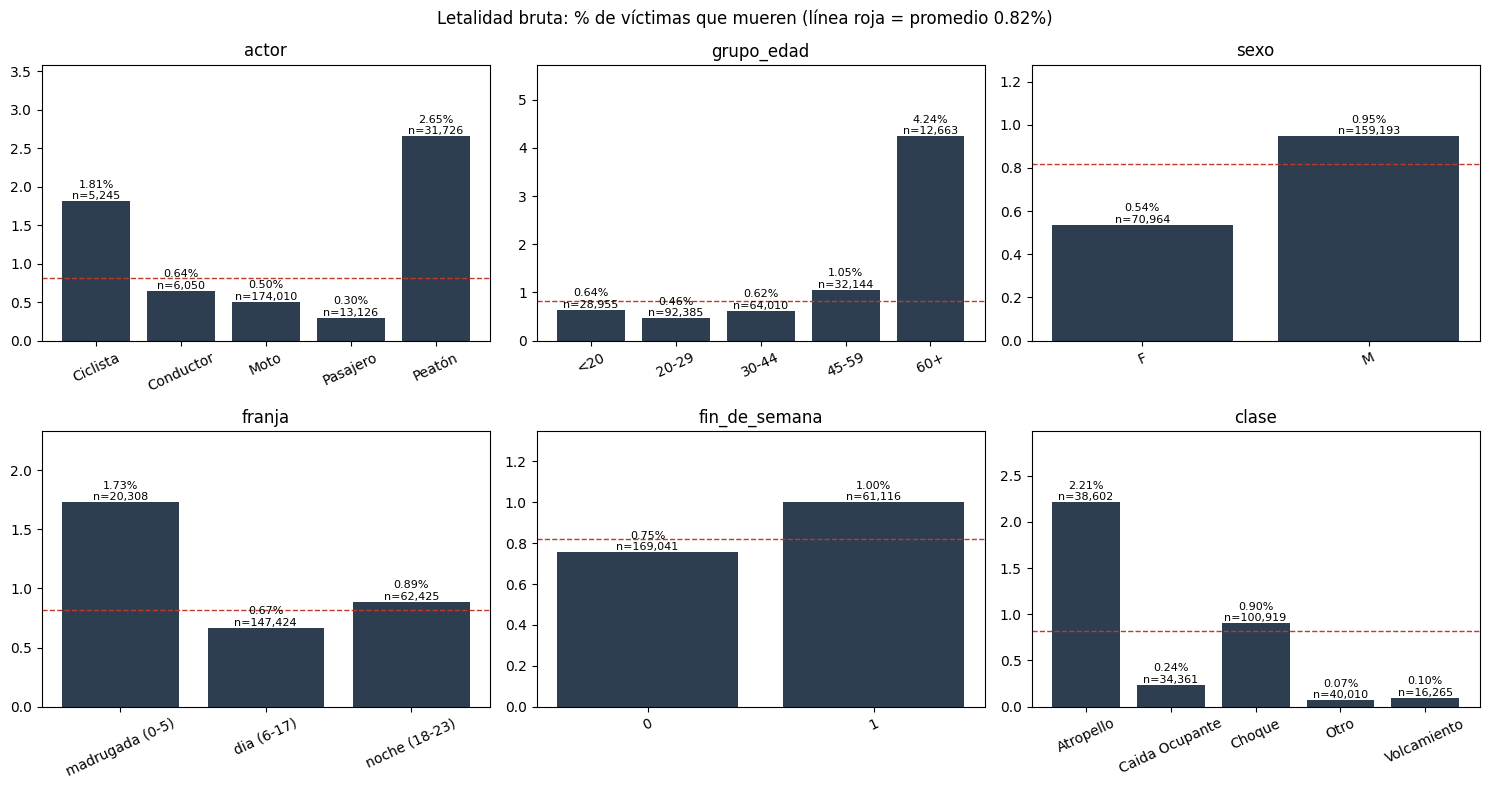

In [5]:
variables = ["actor", "grupo_edad", "sexo", "franja", "fin_de_semana", "clase"]
promedio = m["muerto"].mean() * 100

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, v in zip(axes.flat, variables):
    t = m.groupby(v, observed=True)["muerto"].agg(["mean", "size"])
    t["mean"] *= 100
    ax.bar(t.index.astype(str), t["mean"], color="#2c3e50")
    ax.axhline(promedio, ls="--", color="#c0392b", lw=1)
    for i, (p, n) in enumerate(zip(t["mean"], t["size"])):
        ax.text(i, p, f"{p:.2f}%\nn={n:,}", ha="center", va="bottom", fontsize=8)
    ax.set_ylim(0, t["mean"].max() * 1.35)
    ax.set_title(v)
    ax.tick_params(axis="x", rotation=25)
fig.suptitle(f"Letalidad bruta: % de víctimas que mueren (línea roja = promedio {promedio:.2f}%)")
plt.tight_layout(); plt.show()

### Conclusión
- **Edad:** es la variable con mayor diferencia. De 60 años en adelante muere el 4,24% de las víctimas, contra 0,46% entre 20 y 29 (×9). La curva tiene forma de J: el mínimo está en 20–29.
- **Actor:** peatón 2,65% y ciclista 1,81%, contra moto 0,50%, conductor 0,64% y pasajero 0,30%. El peatón es ~5 veces más letal que la moto.
- **Franja:** madrugada (0–5 h) 1,73%, contra 0,67% de día (×2,6). La noche (18–23 h) queda en el medio (0,89%).
- **Sexo:** hombres 0,95% y mujeres 0,54% (×1,8).
- **Fin de semana:** 1,00% contra 0,75% entre semana (×1,3).
- **Clase:** atropello 2,21% y choque 0,90%, contra caída de ocupante 0,24%, volcamiento 0,10% y otro 0,07%. Repite el patrón del actor, porque atropello ≈ peatón.
- Son efectos **brutos**: las variables están mezcladas (los peatones son mayores, de madrugada salen más hombres, el fin de semana tiene más madrugadas). El modelo completo los separa.

### Decisión
- Todas las variables pasan al modelo completo. Las referencias son moto, 20–29 años, hombre, de día y entre semana: el grupo más numeroso y de menor riesgo, para que los OR se lean como "cuántas veces más".
- La clase se deja solo para la prueba de sensibilidad (3.4).

## 3 · Modelo completo
Todas las variables juntas: el efecto de cada una descontando las demás.
Como morir es raro (<1%), el *odds ratio* (OR) se lee como "cuántas veces más probable".

#### 3.1 Ajuste

In [6]:
formula = ("muerto ~ C(actor, Treatment('Moto')) + C(grupo_edad, Treatment('20-29'))"
           " + C(sexo, Treatment('M')) + C(franja, Treatment('dia (6-17)'))"
           " + fin_de_semana + cuarentena + C(ano_c)")

modelo = smf.logit(formula, data=m).fit(disp=0, cov_type="cluster", cov_kwds={"groups": m["incidente"]})

def tabla_or(res):
    ic = res.conf_int()
    t = pd.DataFrame({"OR": np.exp(res.params), "IC95_inf": np.exp(ic[0]),
                      "IC95_sup": np.exp(ic[1]), "p": res.pvalues}).drop("Intercept")
    t.index = t.index.str.replace(r"C\((\w+).*\[T\.(.+)\]$", r"\1 = \2", regex=True)
    return t

ors = tabla_or(modelo)
print(f"Pseudo R² de McFadden: {modelo.prsquared:.3f} · n = {int(modelo.nobs):,}")
ors[~ors.index.str.startswith("ano_c")].round(3)

Pseudo R² de McFadden: 0.100 · n = 230,157


,OR,IC95_inf,IC95_sup,p
actor = Ciclista,2.782,2.224,3.481,0.000
actor = Conductor,0.851,0.615,1.179,0.332
actor = Pasajero,0.481,0.346,0.668,0.000
actor = Peatón,3.377,3.027,3.767,0.000
grupo_edad = <20,1.027,0.853,1.237,0.775
grupo_edad = 30-44,1.311,1.142,1.504,0.000
grupo_edad = 45-59,1.772,1.533,2.049,0.000
grupo_edad = 60+,5.740,4.987,6.607,0.000
sexo = F,0.537,0.478,0.603,0.000
franja = madrugada (0-5),3.212,2.817,3.662,0.000


#### 3.2 Gráfica de efectos (odds ratios con IC 95%)

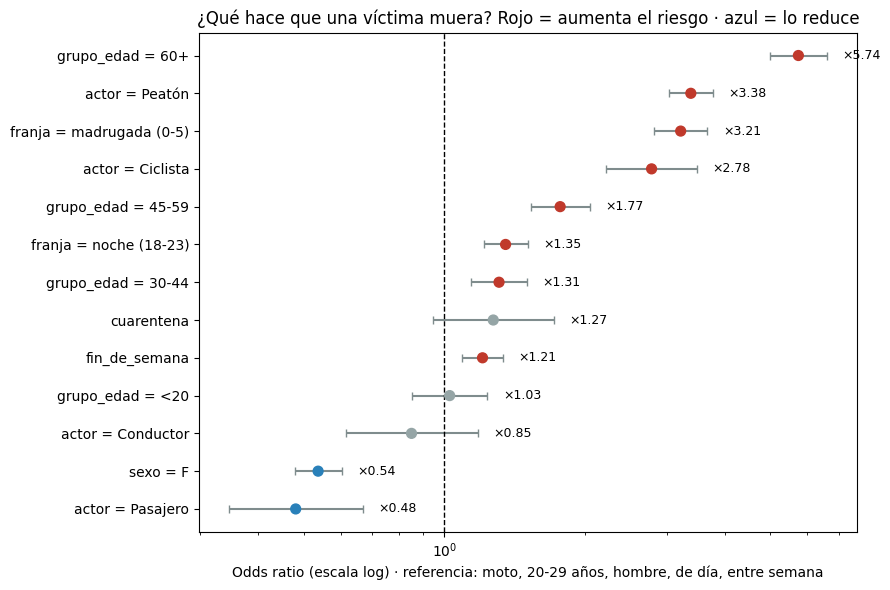

In [7]:
t = ors[~ors.index.str.startswith("ano_c")].sort_values("OR")
colores = ["#c0392b" if (lo > 1) else ("#2980b9" if hi < 1 else "#95a5a6")
           for lo, hi in zip(t["IC95_inf"], t["IC95_sup"])]

fig, ax = plt.subplots(figsize=(9, 6))
ax.errorbar(t["OR"], range(len(t)), xerr=[t["OR"] - t["IC95_inf"], t["IC95_sup"] - t["OR"]],
            fmt="none", ecolor="#7f8c8d", capsize=3)
ax.scatter(t["OR"], range(len(t)), color=colores, zorder=3, s=50)
for i, v in enumerate(t["OR"]):
    ax.text(t["IC95_sup"].iloc[i] * 1.08, i, f"×{v:.2f}", va="center", fontsize=9)
ax.axvline(1, ls="--", color="black", lw=1)
ax.set_xscale("log")
ax.set_yticks(range(len(t)), t.index)
ax.set_xlabel("Odds ratio (escala log) · referencia: moto, 20-29 años, hombre, de día, entre semana")
ax.set_title("¿Qué hace que una víctima muera? Rojo = aumenta el riesgo · azul = lo reduce")
plt.tight_layout(); plt.show()

#### 3.3 ¿Cambia algo al ajustar? Bruto vs. ajustado

In [8]:
def or_bruto(var, nivel, ref):
    s = m[m[var].astype(str).isin([nivel, ref])]
    tab = pd.crosstab(s[var].astype(str), s["muerto"])
    return (tab.loc[nivel, 1] / tab.loc[nivel, 0]) / (tab.loc[ref, 1] / tab.loc[ref, 0])

comparar = pd.DataFrame([
    ("Peatón vs. moto", or_bruto("actor", "Peatón", "Moto"), ors.loc["actor = Peatón", "OR"]),
    ("Ciclista vs. moto", or_bruto("actor", "Ciclista", "Moto"), ors.loc["actor = Ciclista", "OR"]),
    ("60+ vs. 20-29", or_bruto("grupo_edad", "60+", "20-29"), ors.loc["grupo_edad = 60+", "OR"]),
    ("Madrugada vs. día", or_bruto("franja", "madrugada (0-5)", "dia (6-17)"), ors.loc["franja = madrugada (0-5)", "OR"]),
    ("Cuarentena vs. resto", or_bruto("cuarentena", "1", "0"), ors.loc["cuarentena", "OR"]),
], columns=["comparación", "OR_bruto", "OR_ajustado"]).set_index("comparación").round(2)
comparar

,OR_bruto,OR_ajustado
comparación,,
Peatón vs. moto,5.41,3.38
Ciclista vs. moto,3.66,2.78
60+ vs. 20-29,9.49,5.74
Madrugada vs. día,2.62,3.21
Cuarentena vs. resto,1.19,1.27


#### 3.4 Sensibilidad: agregando la clase de incidente
La clase casi coincide con el actor (atropello ≈ peatón), por eso va aparte.

In [9]:
modelo_clase = smf.logit(formula + " + C(clase, Treatment('Choque'))", data=m).fit(
    disp=0, cov_type="cluster", cov_kwds={"groups": m["incidente"]})
ors_clase = tabla_or(modelo_clase)

claves = ["actor = Peatón", "actor = Ciclista", "grupo_edad = 60+", "franja = madrugada (0-5)", "cuarentena"]
pd.DataFrame({"OR_sin_clase": ors.loc[claves, "OR"], "OR_con_clase": ors_clase.loc[claves, "OR"]}).round(2)

,OR_sin_clase,OR_con_clase
actor = Peatón,3.38,2.95
actor = Ciclista,2.78,1.79
grupo_edad = 60+,5.74,5.85
franja = madrugada (0-5),3.21,3.38
cuarentena,1.27,1.32


### Conclusión
**Qué aumenta el riesgo de morir** (OR ajustado, IC 95%; referencia: moto, 20–29 años, hombre, de día, entre semana)
| Factor | OR | IC 95% |
|---|---|---|
| 60 años o más | **5,74** | 4,99 – 6,61 |
| Peatón | **3,38** | 3,03 – 3,77 |
| Madrugada (0–5 h) | **3,21** | 2,82 – 3,66 |
| Ciclista | 2,78 | 2,22 – 3,48 |
| 45–59 años | 1,77 | 1,53 – 2,05 |
| Noche (18–23 h) | 1,35 | 1,21 – 1,51 |
| 30–44 años | 1,31 | 1,14 – 1,50 |
| Fin de semana | 1,21 | 1,09 – 1,34 |
| Mujer | 0,54 | 0,48 – 0,60 |
| Pasajero | 0,48 | 0,35 – 0,67 |
| Cuarentena | 1,27 | 0,95 – 1,72 (p = 0,11) |

- **Edad y actor son los factores más fuertes**, aunque se reducen al ajustar: 60+ pasa de ×9,5 a ×5,7 y peatón de ×5,4 a ×3,4. Parte de su efecto bruto se debía a que los peatones son mayores.
- **La madrugada sube al ajustar** (de ×2,6 a ×3,2): no se explica por quién sale de noche, porque de noche salen más jóvenes en moto, el grupo de menor riesgo. Como la velocidad nocturna apenas sube ~4% (Parte 6 de la exploración), el riesgo de la madrugada se debe sobre todo a otros factores (alcohol, cansancio, visibilidad, respuesta médica).
- **Cuarentena:** ×1,27 ajustada por actor, edad, sexo, hora y año. Va en la dirección esperada, pero no es significativa (p = 0,11). Confirma lo de la exploración.
- **Robustez:** al agregar la clase de incidente, la edad (×5,85), la madrugada (×3,38) y la cuarentena (×1,32) casi no cambian. Solo baja el ciclista (×1,79), porque parte de su riesgo depende del tipo de choque.
- A igual actor, edad y hora, la mujer tiene la mitad del riesgo (×0,54). Es descriptivo; no se interpreta como causa.
- Pseudo R² = 0,10, esperable para un evento raro (<1%). La capacidad de discriminar se mide con el AUC (Parte 4).

### Decisión
- **D22:** el modelo principal es el de la 3.1 (sin clase). La clase va como prueba de sensibilidad.
- **D23:** la reducción de velocidad se presenta como la medida que protege a **los más vulnerables**: peatones, ciclistas y mayores de 60, que son los que más riesgo tienen de morir. El carril de motos protege por **volumen** (la moto es ~75% de las víctimas, aunque con menor letalidad individual).
- El riesgo de la madrugada se reporta como hallazgo aparte (D20), no como argumento para reducir la velocidad.

## 4 · Validación
Entrenar con 2014–2019 y probar con 2020–sep 2021 (años que el modelo no vio).
Este modelo no lleva año ni cuarentena, porque no se pueden estimar para años nuevos.

In [10]:
formula_val = ("muerto ~ C(actor, Treatment('Moto')) + C(grupo_edad, Treatment('20-29'))"
               " + C(sexo, Treatment('M')) + C(franja, Treatment('dia (6-17)')) + fin_de_semana")
entreno, prueba = m[m["ano"] <= 2019], m[m["ano"] >= 2020]

mod_val = smf.logit(formula_val, data=entreno).fit(disp=0)
mod_actor = smf.logit("muerto ~ C(actor)", data=entreno).fit(disp=0)
p_val = mod_val.predict(prueba)
p_actor = mod_actor.predict(prueba)

print(f"Entrenamiento: {len(entreno):,} víctimas · prueba: {len(prueba):,}")
print(f"AUC modelo completo: {roc_auc_score(prueba['muerto'], p_val):.3f}")
print(f"AUC solo con el actor: {roc_auc_score(prueba['muerto'], p_actor):.3f}")
print(f"Brier: {brier_score_loss(prueba['muerto'], p_val):.5f} "
      f"(sin modelo: {brier_score_loss(prueba['muerto'], np.full(len(prueba), entreno['muerto'].mean())):.5f})")
print(f"Muertos esperados en 2020–2021: {p_val.sum():.0f} · observados: {prueba['muerto'].sum()}")

Entrenamiento: 186,678 víctimas · prueba: 43,479
AUC modelo completo: 0.760
AUC solo con el actor: 0.665
Brier: 0.00800 (sin modelo: 0.00814)
Muertos esperados en 2020–2021: 353 · observados: 357


#### 4.1 Calibración: ¿el riesgo que predice se cumple?

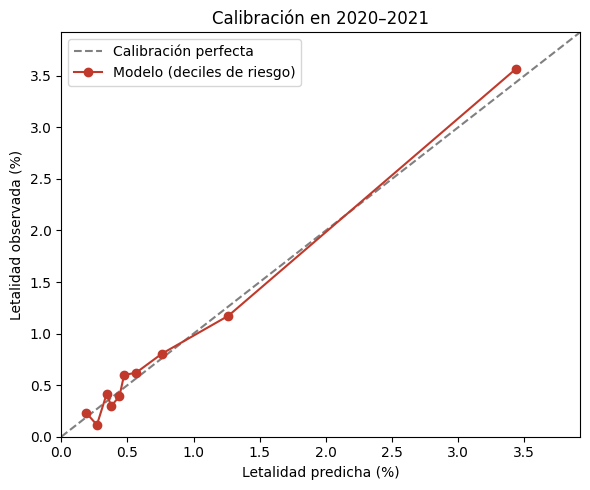

,pred,obs,n
grupo,,,
0,0.19,0.23,4348
1,0.27,0.11,4348
2,0.34,0.41,4348
3,0.38,0.30,4348
4,0.44,0.39,4348
5,0.47,0.60,4347
6,0.57,0.62,4348
7,0.76,0.80,4348
8,1.26,1.17,4348


In [11]:
cal = pd.DataFrame({"pred": p_val, "obs": prueba["muerto"]})
cal["grupo"] = pd.qcut(cal["pred"].rank(method="first"), 10, labels=False)
cal = cal.groupby("grupo").agg(pred=("pred", "mean"), obs=("obs", "mean"), n=("obs", "size")) * [100, 100, 1]

fig, ax = plt.subplots(figsize=(6, 5))
lim = max(cal["pred"].max(), cal["obs"].max()) * 1.1
ax.plot([0, lim], [0, lim], ls="--", color="grey", label="Calibración perfecta")
ax.plot(cal["pred"], cal["obs"], marker="o", color="#c0392b", label="Modelo (deciles de riesgo)")
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel("Letalidad predicha (%)"); ax.set_ylabel("Letalidad observada (%)")
ax.set_title("Calibración en 2020–2021"); ax.legend()
plt.tight_layout(); plt.show()
cal.round(2)

### Conclusión
Modelo entrenado con 2014–2019 (186.678 víctimas) y probado con 2020–sep 2021 (43.479 víctimas), años que no vio.

| Prueba | Resultado | Lectura |
|---|---|---|
| AUC | **0,760** | Discriminación aceptable/buena: acierta 76 de cada 100 comparaciones entre una víctima que murió y una que no |
| AUC solo con el actor | 0,665 | La edad, el sexo y la hora mejoran bastante la predicción |
| Brier | 0,00800 (sin modelo 0,00814) | Mejora pequeña, esperable en un evento raro (<1%) |
| Muertos esperados vs observados | **353 vs 357** | Error del 1% en el total |

- **Calibración:** las predicciones siguen la diagonal. Cuando el modelo predice 3,4% de riesgo, muere el 3,6%. Las diferencias en los grupos de bajo riesgo se deben a que tienen muy pocos muertos (5–10 por grupo).
- **El riesgo está concentrado:** el 10% de las víctimas de mayor riesgo tiene una letalidad 15 veces mayor que el 10% de menor riesgo (3,56% vs 0,23%) y **concentra el 43% de los muertos**. El 20% de mayor riesgo concentra el 58%.
- El modelo generaliza: funciona en años que no vio, incluidos los de la pandemia.

### Decisión
- **D24:** el modelo logístico se considera validado (AUC 0,76, calibrado, error del 1% en muertos totales). Sus probabilidades se pueden usar en el Monte Carlo para traducir incidentes graves en muertes esperadas según el perfil de las víctimas de cada corredor.
- El hallazgo de concentración (10% → 43% de los muertos) se usa en la recomendación: las medidas deben priorizar donde hay más peatones, ciclistas y mayores de 60.

## 5 · Escenarios: probabilidad de morir según el perfil
Con el modelo completo, en un día normal de 2019.

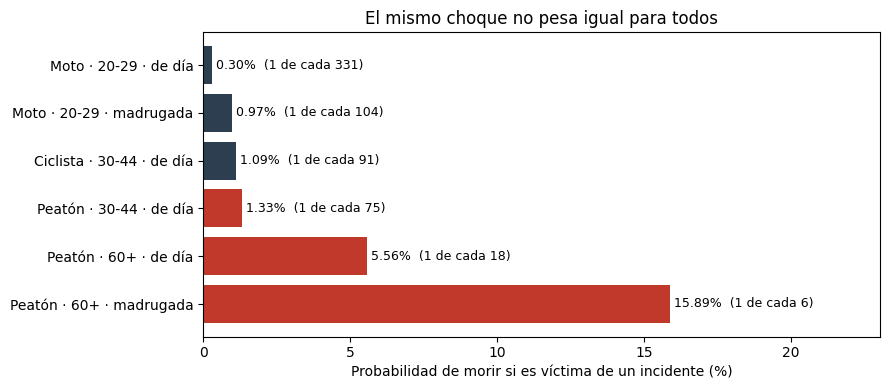

,perfil,prob_%,1_de_cada
0,Moto · 20-29 · de día,0.30,331
1,Moto · 20-29 · madrugada,0.97,104
2,Ciclista · 30-44 · de día,1.09,91
3,Peatón · 30-44 · de día,1.33,75
4,Peatón · 60+ · de día,5.56,18
5,Peatón · 60+ · madrugada,15.89,6


In [12]:
perfiles = pd.DataFrame([
    ("Moto · 20-29 · de día",         "Moto",     "20-29", "M", "dia (6-17)"),
    ("Moto · 20-29 · madrugada",      "Moto",     "20-29", "M", "madrugada (0-5)"),
    ("Ciclista · 30-44 · de día",     "Ciclista", "30-44", "M", "dia (6-17)"),
    ("Peatón · 30-44 · de día",       "Peatón",   "30-44", "M", "dia (6-17)"),
    ("Peatón · 60+ · de día",         "Peatón",   "60+",   "M", "dia (6-17)"),
    ("Peatón · 60+ · madrugada",      "Peatón",   "60+",   "M", "madrugada (0-5)"),
], columns=["perfil", "actor", "grupo_edad", "sexo", "franja"])
perfiles["fin_de_semana"], perfiles["cuarentena"], perfiles["ano_c"] = 0, 0, "2019"
perfiles["prob_%"] = modelo.predict(perfiles) * 100
perfiles["1_de_cada"] = (100 / perfiles["prob_%"]).round(0).astype(int)

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(perfiles["perfil"], perfiles["prob_%"],
        color=["#c0392b" if a == "Peatón" else "#2c3e50" for a in perfiles["actor"]])
for i, (p, n) in enumerate(zip(perfiles["prob_%"], perfiles["1_de_cada"])):
    ax.text(p, i, f" {p:.2f}%  (1 de cada {n})", va="center", fontsize=9)
ax.set_xlim(0, perfiles["prob_%"].max() * 1.45)
ax.invert_yaxis()
ax.set_xlabel("Probabilidad de morir si es víctima de un incidente (%)")
ax.set_title("El mismo choque no pesa igual para todos")
plt.tight_layout(); plt.show()
perfiles[["perfil", "prob_%", "1_de_cada"]].round(2)

In [13]:
# 5.1 Comprobación con datos reales del perfil extremo
real = m[(m["actor"] == "Peatón") & (m["grupo_edad"] == "60+")].groupby("franja", observed=True)["muerto"].agg(
    victimas="size", muertos="sum")
real["letalidad_real_%"] = (real["muertos"] / real["victimas"] * 100).round(2)
real

,victimas,muertos,letalidad_real_%
franja,,,
madrugada (0-5),236,33,13.98
dia (6-17),4914,310,6.31
noche (18-23),1840,133,7.23


### Conclusión
Probabilidad de morir si es víctima de un incidente (hombre, entre semana, 2019):

| Perfil | Probabilidad | 1 de cada |
|---|---|---|
| Moto · 20–29 · de día | 0,30% | 331 |
| Moto · 20–29 · madrugada | 0,97% | 104 |
| Ciclista · 30–44 · de día | 1,09% | 91 |
| Peatón · 30–44 · de día | 1,33% | 75 |
| Peatón · 60+ · de día | 5,56% | 18 |
| Peatón · 60+ · madrugada | **15,89%** | **6** |

- **El riesgo de morir cambia ~53 veces según el perfil de la víctima.**
- **Los factores se multiplican.** En cualquier perfil, la madrugada triplica el riesgo (moto: 0,30% → 0,97%; peatón mayor: 5,56% → 15,89%). Tener más de 60 años multiplica por ~4 el riesgo del peatón (1,33% → 5,56%).
- **Comprobación con datos reales.** El modelo no tiene interacciones, así que en combinaciones raras podría exagerar. Se comparó con lo observado en peatones de 60 años o más:

| Franja | Víctimas | Muertos | Letalidad real | Modelo |
|---|---|---|---|---|
| Madrugada | 236 | 33 | **13,98%** | 15,89% |
| Día | 4.914 | 310 | 6,31% | 5,56% |
| Noche | 1.840 | 133 | 7,23% | — |

- Las cifras reales están cerca de las del modelo. Las diferencias son esperables: el perfil del modelo es "hombre entre semana" y los datos reales mezclan sexos y días, y en la madrugada solo hay 236 casos.

### Decisión
- Para el pitch se usa la **cifra real**: *"en un incidente, un motociclista joven de día muere 1 de cada 331 veces; un peatón mayor de 60 de madrugada, 1 de cada 7"*.

## 6 · Resumen

### Qué se hizo
**Pregunta:** cuando alguien es víctima de un incidente vial en Medellín, ¿qué hace que muera y no solo resulte herido?

**Datos.** Se usó el archivo de víctimas de MEData (ene 2014 – sep 2021) y no la base del ITM. En la exploración encontramos que la base del ITM registra solo entre el 52% y el 91% de los muertos, según el año, mientras que el archivo de víctimas coincide con la cifra oficial del Distrito (2019: 247 contra 251) (D13, D16).
- 235.843 víctimas reales; entraron al modelo **230.157 (97,6%) con 1.887 muertos**. Se excluyeron las víctimas sin edad o con sexo distinto de M/F.

**Método: regresión logística.** Estima cómo cambia la probabilidad de morir según cada característica, **descontando el efecto de las demás**. Así, por ejemplo, se separa el efecto de ser peatón del efecto de ser mayor, porque muchos peatones víctimas son mayores.
- **Variable a explicar:** murió (1) o resultó herido (0).
- **Variables explicativas:** actor vial, grupo de edad, sexo, franja horaria, fin de semana, cuarentena (mar–ago 2020) y año.
- **Referencia:** motociclista de 20 a 29 años, hombre, de día y entre semana. Es el grupo más numeroso y de menor riesgo, así que cada resultado se lee como "cuántas veces más riesgo que la referencia".
- **Resultado:** *odds ratios* (OR) con intervalos de confianza del 95%. Como morir es raro (<1%), el OR se lee como "cuántas veces más probable".
- **Errores estándar agrupados por incidente:** las víctimas de un mismo choque no son independientes. Sin esta corrección, los intervalos salen falsamente estrechos.

**Controles de calidad**
1. **Bruto contra ajustado:** se comparó el efecto de cada variable sola contra su efecto en el modelo completo.
2. **Sensibilidad:** se repitió el modelo agregando la clase de incidente, para ver si los resultados cambiaban.
3. **Validación fuera de muestra:** se entrenó con 2014–2019 y se probó con 2020–2021, años que el modelo no vio. Se midieron la discriminación (AUC), la calibración y los muertos esperados contra los observados.
4. **Comprobación con datos reales:** las probabilidades de los perfiles extremos se compararon con la letalidad observada.

### Resultados
**Qué aumenta el riesgo de morir** (OR ajustado)
| Factor | OR | IC 95% |
|---|---|---|
| 60 años o más | **5,74** | 4,99 – 6,61 |
| Peatón | **3,38** | 3,03 – 3,77 |
| Madrugada (0–5 h) | **3,21** | 2,82 – 3,66 |
| Ciclista | 2,78 | 2,22 – 3,48 |
| 45–59 años | 1,77 | 1,53 – 2,05 |
| Noche (18–23 h) | 1,35 | 1,21 – 1,51 |
| Fin de semana | 1,21 | 1,09 – 1,34 |
| Mujer | 0,54 | 0,48 – 0,60 |
| Cuarentena | 1,27 | 0,95 – 1,72 (p = 0,11) |

1. **La edad es el factor más fuerte.** Una víctima de 60 años o más tiene casi 6 veces más riesgo de morir que una de 20 a 29.
2. **Peatones y ciclistas son los más vulnerables** (×3,4 y ×2,8 frente a la moto): sin carrocería, el cuerpo recibe todo el impacto.
3. **La madrugada triplica el riesgo, y no por quién sale a esa hora.** Al ajustar, el efecto sube (de ×2,6 a ×3,2). Como la velocidad nocturna apenas sube ~4% (exploración, Parte 6), se debe sobre todo a otros factores: alcohol, cansancio, visibilidad, respuesta médica.
4. **La cuarentena (calles vacías y más velocidad) aumenta el riesgo ×1,27**, ya ajustada por actor, edad, hora y año. Va en la dirección esperada, pero no es significativa. Es evidencia consistente, no prueba (D19).
5. **Los resultados son robustos:** al agregar la clase de incidente, la edad, la madrugada y la cuarentena casi no cambian.

**Qué tan bueno es el modelo**
- **AUC 0,76** en años que no vio: acierta 76 de cada 100 comparaciones entre una víctima que murió y una que no. Con solo el actor, el AUC es 0,665.
- **Predijo 353 muertos en 2020–2021 y hubo 357** (1% de error). Las probabilidades están bien calibradas.
- **El riesgo está concentrado:** el 10% de las víctimas de mayor riesgo concentra el 43% de los muertos.

**El mismo choque no pesa igual para todos**
- Motociclista de 20–29 años, de día: muere **1 de cada 331**.
- Peatón de 60 años o más, de madrugada: muere **1 de cada 7** (dato real: 33 de 236).

### Qué significa para el proyecto
- **La reducción de velocidad protege sobre todo a los más vulnerables:** peatones, ciclistas y mayores de 60. Los corredores donde estas víctimas son frecuentes deben ir primero.
- **El carril exclusivo de motos protege por volumen.** La moto tiene la menor letalidad individual, pero es ~75% de las víctimas y está en ~85% de los incidentes graves.
- **El modelo se usa en el Monte Carlo (D24)** para convertir los incidentes graves de cada corredor en muertes esperadas, según el perfil de sus víctimas.
- **El riesgo de la madrugada es un hallazgo aparte.** No se resuelve con la velocidad, sino con medidas complementarias: control de alcohol, iluminación, tiempo de respuesta médica.

### Limitaciones
- El archivo de víctimas termina en septiembre de 2021, así que no cubre los años en que más suben las muertes (2023–2024).
- No hay datos de velocidad del vehículo, uso de casco, alcohol ni tiempo de llegada de la ambulancia. Por eso el pseudo R² es bajo (0,10), lo esperable en un evento raro.
- Se excluyó el 3,2% de los muertos por no tener la edad registrada.
- El modelo no tiene interacciones. En combinaciones raras puede desviarse un poco (peatón 60+ de madrugada: 15,9% predicho contra 14,0% real).